# Universidad Autonoma de Aguascalientes
# Departamento: Ciencias de la Computacion
# Carrera: Ingenieria en Computacion Inteligente
## Curso: Lenguajes Inteligentes
## Maestro: Dr.Francisco Javier Lunas Rosas
## Alumno: Juan Emmanuel Suarez Garcia
## Semestre: Agosto_Diciembre del 2026

## Practica #8. MORFOLOGIA MATEMATICA

### La morfología matemática de imágenes es un conjunto de técnicas de procesamiento digital basadas en la forma y estructura geométrica de los objetos dentro de una imagen. En esta práctica diseñaremos un programa en Python que implemente las operaciones morfológicas fundamentales de erosión, dilatación, apertura y cierre utilizando la librería OpenCV

## Paso 1: Importamos librerias necesarias

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

## Paso 2: Cargamos la imagen

In [23]:
imagen_pil = Image.open("C:/Users/maluc/Downloads/pexels-lestrade84-17811.jpg").convert('L')
imagen_pil = imagen_pil.resize((300, 300))
matriz_gris = np.array(imagen_pil)
imagen_binaria = np.where(matriz_gris > 127, 1, 0).astype(np.uint8)

## Paso 3: Binarizamos

In [24]:
UMBRAL = 127
imagen_binaria = np.where(matriz_gris > 127, 1, 0).astype(np.uint8)

## Paso 4: Definimos el Kernel en una matriz de 3x3

In [25]:
kernel = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
], dtype=np.uint8)

## Paso 5: Aplicamos la erosion

In [26]:
def erosion(img, kernel):
    filas, columnas = img.shape
    k_filas, k_cols = kernel.shape
    pad_h, pad_w = k_filas // 2, k_cols // 2
    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    resultado = np.zeros_like(img)

    for i in range(filas):
        for j in range(columnas):
            region = img_padded[i:i + k_filas, j:j + k_cols]

            if np.all(region[kernel == 1] == 1):
                resultado[i, j] = 1
            else:
                resultado[i, j] = 0

    return resultado

## Paso 6: Erosion aplicada a la imagen

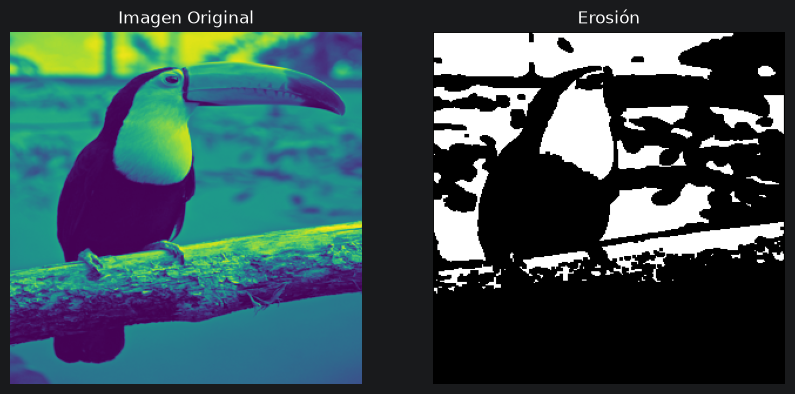

In [33]:
img_erosionada = erosion(imagen_binaria, kernel)

plt.figure(figsize=(10, 5))

# Original Real
plt.subplot(1, 2, 1)
plt.imshow(imagen_pil)
plt.title("Imagen Original")
plt.axis('off')

# Resultado Erosión
plt.subplot(1, 2, 2)
plt.imshow(img_erosionada, cmap='gray')
plt.title("Erosión")
plt.axis('off')

plt.show()

## Paso 7: Definimos y aplicamos la dilatacion

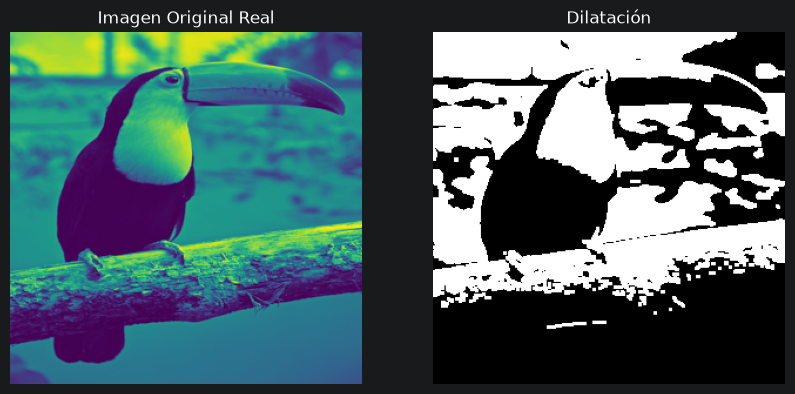

In [28]:
def dilatacion(img, kernel):
    filas, columnas = img.shape
    k_filas, k_cols = kernel.shape
    pad_h, pad_w = k_filas // 2, k_cols // 2
    img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)
    resultado = np.zeros_like(img)

    for i in range(filas):
        for j in range(columnas):
            region = img_padded[i:i + k_filas, j:j + k_cols]

            if np.any(region[kernel == 1] == 1):
                resultado[i, j] = 1
            else:
                resultado[i, j] = 0

    return resultado

img_dilatada = dilatacion(imagen_binaria, kernel)

plt.figure(figsize=(10, 5))

# Original Real
plt.subplot(1, 2, 1)
plt.imshow(imagen_pil)
plt.title("Imagen Original")
plt.axis('off')

# Resultado Dilatación
plt.subplot(1, 2, 2)
plt.imshow(img_dilatada, cmap='gray')
plt.title("Dilatación")
plt.axis('off')

plt.show()

## Paso 8: Aplicamos apertura

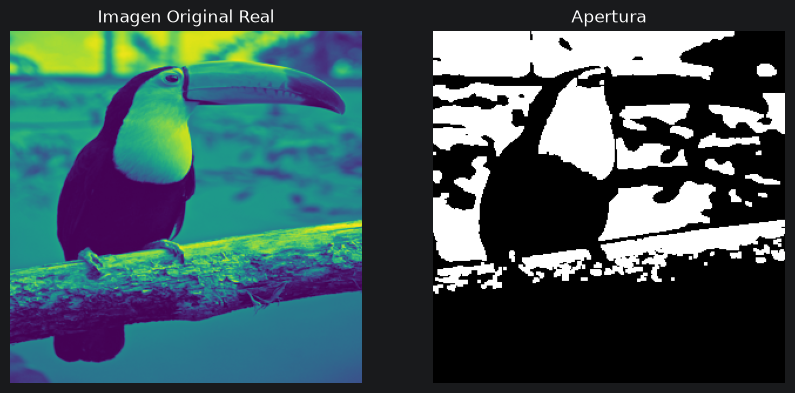

In [29]:
def apertura(img, kernel):
    return dilatacion(erosion(img, kernel), kernel)

img_apertura = apertura(imagen_binaria, kernel)

plt.figure(figsize=(10, 5))

# Original Real
plt.subplot(1, 2, 1)
plt.imshow(imagen_pil)
plt.title("Imagen Original")
plt.axis('off')

# Resultado Apertura
plt.subplot(1, 2, 2)
plt.imshow(img_apertura, cmap='gray')
plt.title("Apertura")
plt.axis('off')

plt.show()

## Paso 9: Aplicamos cierre

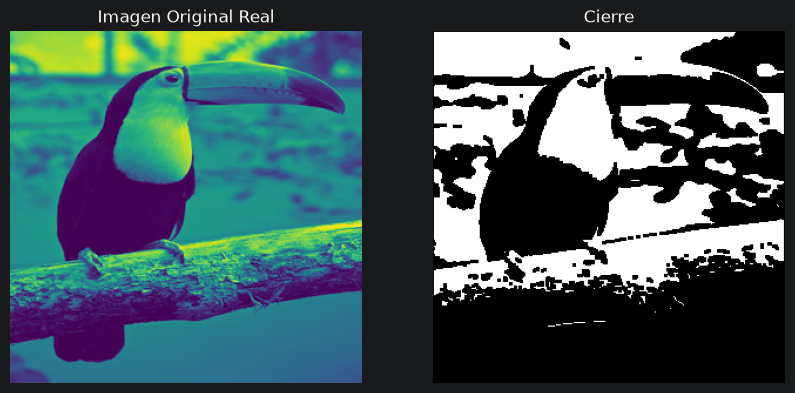

In [30]:
def cierre(img, kernel):
    return erosion(dilatacion(img, kernel), kernel)

img_cierre = cierre(imagen_binaria, kernel)

plt.figure(figsize=(10, 5))

# Original Real
plt.subplot(1, 2, 1)
plt.imshow(imagen_pil)
plt.title("Imagen Original")
plt.axis('off')

# Resultado Cierre
plt.subplot(1, 2, 2)
plt.imshow(img_cierre, cmap='gray')
plt.title("Cierre")
plt.axis('off')

plt.show()